# 1.7 Geodetic GNSS data

This notebook downloads daily GNSS position time series from the [Nevada Geodetic Laboratory](https://geodesy.unr.edu) (NGL) at the University of Nevada, Reno. NGL processes data from thousands of permanent GNSS stations worldwide and publishes daily position solutions as plain text files, one file per station.

**What the data is.** A permanent GNSS station measures its own position, every day, to a few millimeters. The time series records ground motion: steady plate tectonic drift, earthquakes (sudden offsets), slow slip events, and seasonal loading from water and snow.

**Reference frame.** We use solutions in **IGS20**, the current realization of the International Terrestrial Reference Frame adopted by the International GNSS Service. Positions are expressed relative to this global frame, so the steady trends you will see are plate motions.

**Data labels:** 📍 In-situ sensor · 🪨 Solid Earth · 📐 Geodesy. At P563 the record also carries 💧 Land water, because the ground there subsides as the aquifer below is drawn down (see the map section at the end).

**Citation.** When using NGL products, cite: Blewitt, G., Hammond, W. C., & Kreemer, C. (2018). Harnessing the GPS data explosion for interdisciplinary science. *Eos*, 99, [doi:10.1029/2018EO104623](https://doi.org/10.1029/2018EO104623).

🖥️ [**Lecture slides — Session 04 (Wed Oct 7)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec04_meet_the_data.html)

In [1]:
import datetime as dt
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch

# pooch logs every download with the full local path; we print what matters (the checksum) ourselves
pooch.get_logger().setLevel("WARNING")

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

## The `.tenv3` format

Each station file at `https://geodesy.unr.edu/gps_timeseries/IGS20/tenv3/IGS20/{STATION}.tenv3` is whitespace-delimited with one header line. The columns include the station name (`site`), the date (`YYMMMDD`), the decimal year (`yyyy.yyyy`), and the position components split into an integer base and a fractional part: `__east(m)`, `_north(m)`, `____up(m)` hold the varying part of the east, north, and up positions in meters. The odd-looking underscores are part of the actual column names, so we inspect the header after parsing rather than assuming it.

We use two stations from the Network of the Americas (NOTA): **P395**, in the Oregon Coast Range above the Cascadia subduction zone, and **P563**, in the southern San Joaquin Valley of California, inside the Pacific–North America plate boundary zone. Their coordinates, and the velocities NGL publishes for them, are fetched from NGL in the last section, with a map.

## Downloading with pooch without a pinned hash

Section [1.6](1.6_data_gallery.md) taught the pattern: download with `pooch`, then pin the printed checksum as `known_hash` so every future run verifies it got the same bytes. That pattern applies to **frozen** files — a released dataset, an archived snapshot, the Natural Earth raster in Chapter 2.2.

These NGL files are **living data**: a new daily solution is appended every day, so the file's checksum changes every day, and a hash pinned today would fail tomorrow — by design, since the file really did change. So here we pass `known_hash=None` and instead *print* the SHA256 of what we actually received. That printed hash is your provenance record: copy it into your notes or run log, and today's analysis is tied to an exact input even though tomorrow's download will differ. If you need bit-identical reruns (a paper, a graded submission), freeze a snapshot — archive the downloaded file (Zenodo, your repo's data release) and pin *that* copy's hash.

One caching caveat: with `known_hash=None`, pooch reuses a cached copy without asking the server. Delete the `.tenv3` file from `data/` when you want today's data instead of the day you first ran this notebook.

In [2]:
BASE_URL = "https://geodesy.unr.edu/gps_timeseries/IGS20/tenv3/IGS20/{station}.tenv3"


def fetch_tenv3(station):
    """Fetch an NGL .tenv3 daily position file (cached by pooch) as a DataFrame."""
    path = pooch.retrieve(
        url=BASE_URL.format(station=station),
        known_hash=None,  # living data: NGL appends a new daily solution every day
        fname=f"{station}.tenv3",
        path=DATA_DIR,
        downloader=pooch.HTTPDownloader(timeout=120),
    )
    print(f"{station}.tenv3 sha256:{pooch.file_hash(path)}")
    # whitespace-delimited text with one header line
    return pd.read_csv(path, sep=r"\s+")


df = fetch_tenv3("P395")
print(df.columns.tolist())

P395.tenv3 sha256:ca15692ccdc6155c54361959c240a9ad01a22fd1455d7b5034c062957f93c6db
['site', 'YYMMMDD', 'yyyy.yyyy', '__MJD', 'week', 'd', 'reflon', '_e0(m)', '__east(m)', '____n0(m)', '_north(m)', 'u0(m)', '____up(m)', '_ant(m)', 'sig_e(m)', 'sig_n(m)', 'sig_u(m)', '__corr_en', '__corr_eu', '__corr_nu', '_latitude(deg)', '_longitude(deg)', '__height(m)']


In [3]:
df.head()

,site,YYMMMDD,yyyy.yyyy,__MJD,week,d,reflon,_e0(m),__east(m),____n0(m),...,_ant(m),sig_e(m),sig_n(m),sig_u(m),__corr_en,__corr_eu,__corr_nu,_latitude(deg),_longitude(deg),__height(m)
0,P395,06JAN25,2006.0671,53760,1359,3,-123.9,3347,0.560065,4987420,...,0.0083,0.000748,0.001125,0.003637,-0.053526,0.039949,-0.344025,45.022279,-123.857527,53.03951
1,P395,06JAN26,2006.0698,53761,1359,4,-123.9,3347,0.560733,4987420,...,0.0083,0.000740,0.001135,0.003557,-0.030311,0.021842,-0.308583,45.022279,-123.857527,53.03502
2,P395,06JAN27,2006.0726,53762,1359,5,-123.9,3347,0.560999,4987420,...,0.0083,0.000735,0.001120,0.003583,-0.023363,0.042888,-0.330909,45.022279,-123.857527,53.04103
3,P395,06JAN28,2006.0753,53763,1359,6,-123.9,3347,0.560352,4987420,...,0.0083,0.000756,0.001132,0.003778,-0.024996,0.024686,-0.365856,45.022279,-123.857527,53.04785
4,P395,06JAN29,2006.0780,53764,1360,0,-123.9,3347,0.560269,4987420,...,0.0083,0.000738,0.001132,0.003582,-0.041592,0.058166,-0.318254,45.022279,-123.857527,53.03961


## Relative displacement

The absolute coordinates are large numbers; what we care about is motion. We subtract the first daily solution from each component, so every series starts at zero and shows displacement in meters since the first observation. We keep the decimal year as the time axis.

In [4]:
def to_relative(df):
    """Return decimal year and east/north/up displacement (m) relative to the first epoch."""
    return pd.DataFrame(
        {
            "decimal_year": df["yyyy.yyyy"],
            "east_m": df["__east(m)"] - df["__east(m)"].iloc[0],
            "north_m": df["_north(m)"] - df["_north(m)"].iloc[0],
            "up_m": df["____up(m)"] - df["____up(m)"].iloc[0],
        }
    )


rel_p395 = to_relative(df)
rel_p395.describe()

,decimal_year,east_m,north_m,up_m
count,7496.000000,7496.000000,7496.000000,7496.000000
mean,2016.360760,-0.064145,-0.032969,-0.001964
std,5.952187,0.039036,0.021217,0.006325
min,2006.067100,-0.135191,-0.074132,-0.034824
25%,2011.216300,-0.098068,-0.051272,-0.006225
50%,2016.346350,-0.066276,-0.033039,-0.002009
75%,2021.501000,-0.028868,-0.014232,0.002251
max,2026.735100,0.003415,0.006054,0.023520


In [5]:
# download both stations and save the relative positions to ./data/
stations = ["P395", "P563"]
series = {}
for station in stations:
    rel = to_relative(fetch_tenv3(station))
    outfile = DATA_DIR / f"gps_{station}_relative_position.csv"
    rel.to_csv(outfile, index=False)
    series[station] = rel
    print(f"{station}: {len(rel)} daily solutions saved to {outfile}")

P395.tenv3 sha256:ca15692ccdc6155c54361959c240a9ad01a22fd1455d7b5034c062957f93c6db
P395: 7496 daily solutions saved to data/gps_P395_relative_position.csv
P563.tenv3 sha256:40e1e393c589c238faccc01a3261cbe33480387260544d8e2baf25afd979f0be
P563: 7555 daily solutions saved to data/gps_P563_relative_position.csv


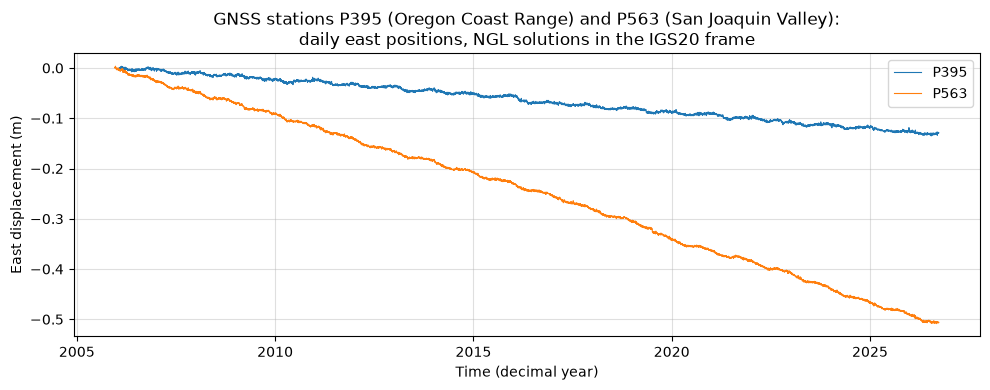

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for station, rel in series.items():
    ax.plot(rel["decimal_year"], rel["east_m"], lw=0.8, label=station)
ax.set_xlabel("Time (decimal year)")
ax.set_ylabel("East displacement (m)")
ax.set_title("GNSS stations P395 (Oregon Coast Range) and P563 (San Joaquin Valley):\n"
             "daily east positions, NGL solutions in the IGS20 frame")
ax.grid(alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

## Station locations and NGL velocities

A time series without its place is half a dataset. NGL publishes each station's coordinates in [`llh.out`](https://geodesy.unr.edu/NGLStationPages/llh.out) (latitude, longitude, ellipsoidal height) and each station's velocity from **MIDAS**, a trend estimator built to be insensitive to steps and seasonal signals (Blewitt et al., 2016, [doi:10.1002/2015JB012552](https://doi.org/10.1002/2015JB012552)). We read two MIDAS files, both from NGL's IGS20 processing:

- [`midas.IGS.txt`](https://geodesy.unr.edu/gps_timeseries/IGS20/midas/midas.IGS.txt): velocities in the IGS20 frame, the frame of the series plotted above, so these are the slopes of that plot;
- [`midas.NA.txt`](https://geodesy.unr.edu/gps_timeseries/IGS20/midas/midas.NA.txt): the same velocities relative to stable North America, which removes the motion of the plate as a whole and leaves the deformation at the plate boundary.

These files are living data too (NGL rewrites them as new solutions arrive), so we log each file's SHA256 and download date instead of pinning a hash. We read the published values rather than re-deriving them; when you fit a trend to these series yourself in section 2.6, compare your number with NGL's.

In [7]:
NGL = "https://geodesy.unr.edu"
STATIONS = ["P395", "P563"]


def fetch_living(url, fname):
    """Fetch a living NGL file (cached by pooch); log its SHA256 and when it was downloaded."""
    path = pooch.retrieve(url, known_hash=None, fname=fname, path=DATA_DIR,
                          downloader=pooch.HTTPDownloader(timeout=120))
    downloaded = dt.datetime.fromtimestamp(Path(path).stat().st_mtime, dt.timezone.utc)
    print(f"{fname}  downloaded {downloaded:%Y-%m-%d %H:%M} UTC  sha256:{pooch.file_hash(path)}")
    return path


def read_llh(path):
    """NGL llh.out columns: station, latitude (deg), longitude (deg), ellipsoidal height (m)."""
    rows = {}
    for line in open(path):
        p = line.split()
        if p and p[0] in STATIONS:
            lon = (float(p[2]) + 180) % 360 - 180  # NGL lists some longitudes outside [-180, 180)
            rows[p[0]] = {"lat_deg": float(p[1]), "lon_deg": lon, "height_m": float(p[3])}
    return pd.DataFrame.from_dict(rows, orient="index")


def read_midas(path):
    """NGL MIDAS columns used here: 4 last epoch of the series (decimal year),
    9-11 east/north/up velocity and 12-14 their uncertainties, all in m/yr."""
    rows = {}
    for line in open(path):
        p = line.split()
        if p and p[0] in STATIONS:
            v = [1000 * float(x) for x in p[8:14]]  # m/yr -> mm/yr
            rows[p[0]] = dict(zip(["ve", "vn", "vu", "se", "sn", "su"], v), last_epoch=float(p[3]))
    return pd.DataFrame.from_dict(rows, orient="index")


coords = read_llh(fetch_living(f"{NGL}/NGLStationPages/llh.out", "llh.out"))
igs = read_midas(fetch_living(f"{NGL}/gps_timeseries/IGS20/midas/midas.IGS.txt", "midas.IGS.txt"))
na = read_midas(fetch_living(f"{NGL}/gps_timeseries/IGS20/midas/midas.NA.txt", "midas.NA.txt"))

stations_table = pd.DataFrame({
    "lat_deg": coords["lat_deg"].round(4),
    "lon_deg": coords["lon_deg"].round(4),
    "east_IGS20": igs["ve"], "north_IGS20": igs["vn"], "up_IGS20": igs["vu"],
    "sig_east": igs["se"], "sig_north": igs["sn"], "sig_up": igs["su"],
    "east_NA": na["ve"], "north_NA": na["vn"],
    "series_end": igs["last_epoch"],
}).round({c: 1 for c in ["east_IGS20", "north_IGS20", "up_IGS20", "sig_east", "sig_north",
                         "sig_up", "east_NA", "north_NA"]})
print("Velocities in mm/yr (NGL MIDAS); series_end is the last epoch MIDAS used, in decimal years.")
stations_table

llh.out  downloaded 2026-10-07 18:10 UTC  sha256:2444099bc20b4e3c3a238a0ce71786e4254b6035ba3d1aad8daf54ffde46c896
midas.IGS.txt  downloaded 2026-10-07 18:10 UTC  sha256:7167571a28fe780762bc5f57fe2fce1cd2e39d12b1b8c5faca6f0b3827f52467
midas.NA.txt  downloaded 2026-10-07 18:10 UTC  sha256:59f66babc7c6e43ff3c8541dd453f6874cb8fde97942e9eff86d025bb3604f75
Velocities in mm/yr (NGL MIDAS); series_end is the last epoch MIDAS used, in decimal years.


,lat_deg,lon_deg,east_IGS20,north_IGS20,up_IGS20,sig_east,sig_north,sig_up,east_NA,north_NA,series_end
P395,45.0223,-123.8575,-6.4,-3.4,0.2,0.2,0.2,0.4,6.9,10.7,2026.7351
P563,35.4187,-119.4212,-23.5,1.7,-7.2,0.2,0.1,0.5,-11.9,14.3,2026.7351


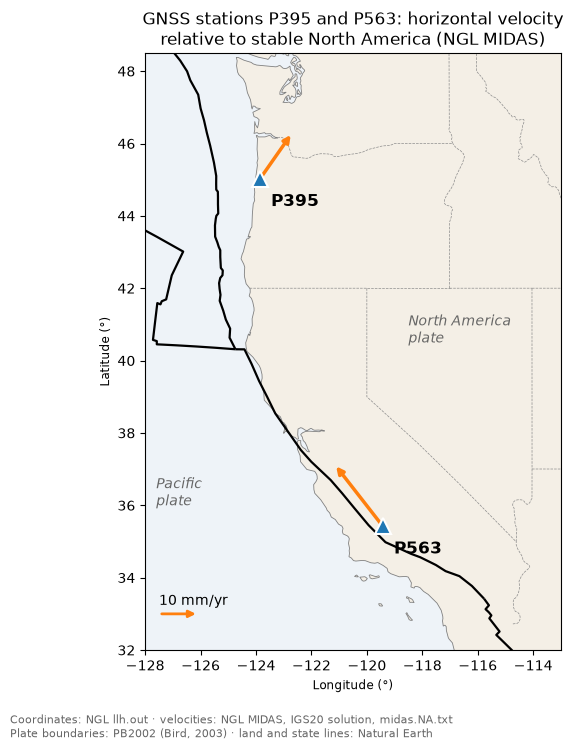

In [8]:
# Basemap layers are frozen files (released versions), so their hashes are pinned.
land = gpd.read_file(pooch.retrieve(
    "https://naciscdn.org/naturalearth/50m/physical/ne_50m_land.zip",
    known_hash="sha256:0b8e670cf80dce9cbebe2a193bc44ba5602758c22e1fa603980553646d7ff162",
    fname="ne_50m_land.zip", path=DATA_DIR))
states = gpd.read_file(pooch.retrieve(
    "https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_1_states_provinces_lines.zip",
    known_hash="sha256:464e762020d198257a07f5f62eb7cbfc287fccbc0a6db788d8068b49844d951e",
    fname="ne_50m_admin_1_states_provinces_lines.zip", path=DATA_DIR))
plates = gpd.read_file(pooch.retrieve(  # PB2002 plate boundaries (Bird, 2003), pinned to one commit
    "https://raw.githubusercontent.com/fraxen/tectonicplates/"
    "339b0c56563c118307b1f4542703047f5f698fae/GeoJSON/PB2002_boundaries.json",
    known_hash="sha256:42b3e0876a7e40f133e958ba7ab85f8851b5c693a046fbc3b138e7751863d92a",
    fname="PB2002_boundaries.json", path=DATA_DIR))

fig, ax = plt.subplots(figsize=(7, 7.5))
ax.set_facecolor("#eef3f8")
land.plot(ax=ax, color="#f4efe6", edgecolor="0.5", lw=0.6)
states.plot(ax=ax, color="0.55", lw=0.5, ls="--")
plates.plot(ax=ax, color="k", lw=1.6)

scale = 0.12  # arrow length: degrees of latitude per mm/yr
for sta, row in coords.iterrows():
    lat, lon = row["lat_deg"], row["lon_deg"]
    k = np.cos(np.deg2rad(lat))
    tip = (lon + na.loc[sta, "ve"] * scale / k, lat + na.loc[sta, "vn"] * scale)
    ax.annotate("", xy=tip, xytext=(lon, lat),
                arrowprops=dict(arrowstyle="-|>", color="C1", lw=2.5))
    ax.plot(lon, lat, "^", ms=12, color="C0", mec="white", mew=1.5, zorder=5)
    ax.text(lon + 0.4, lat - 0.4, sta, fontsize=12, fontweight="bold", va="top")

lat_bar = 33.0  # 10 mm/yr scale arrow, offshore
ax.annotate("", xy=(-127.5 + 10 * scale / np.cos(np.deg2rad(lat_bar)), lat_bar), xytext=(-127.5, lat_bar),
            arrowprops=dict(arrowstyle="-|>", color="C1", lw=2))
ax.text(-127.5, lat_bar + 0.25, "10 mm/yr")
ax.text(-127.6, 36.0, "Pacific\nplate", color="0.4", style="italic")
ax.text(-118.5, 40.5, "North America\nplate", color="0.4", style="italic")

ax.set_xlim(-128, -113)
ax.set_ylim(32, 48.5)
ax.set_aspect(1 / np.cos(np.deg2rad(40)))
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title("GNSS stations P395 and P563: horizontal velocity\nrelative to stable North America (NGL MIDAS)")
fig.text(0.01, 0.01, "Coordinates: NGL llh.out · velocities: NGL MIDAS, IGS20 solution, midas.NA.txt\n"
         "Plate boundaries: PB2002 (Bird, 2003) · land and state lines: Natural Earth",
         fontsize=8, color="0.4")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**How to read the map and the table.** The arrows show motion relative to stable North America, the deformation at the plate boundary. The series plotted earlier are in IGS20, where the whole North American plate also moves, so their slopes should match the `_IGS20` columns, not the `_NA` ones. The difference between the two frames is the motion of the plate itself.

- **P395** sits above the Cascadia subduction zone. Its northeast motion relative to North America is commonly attributed to elastic loading of the upper plate while the megathrust offshore is locked, with a contribution from rotation of the Oregon forearc (McCaffrey et al., 2013). Compare its vertical rate with its uncertainty before calling it uplift.
- **P563** sits in the Pacific–North America plate boundary zone. Its northwest motion records shear across that zone, and its negative vertical rate is subsidence consistent with groundwater extraction from the Central Valley aquifer system. One GNSS record, two Earth systems: 🪨 Solid Earth and 💧 Land water.

The east components drift steadily, at the MIDAS rates in the table: plate motion and plate-boundary deformation measured directly. Look closely and you can also see seasonal wiggles and, depending on the station and period, small offsets from earthquakes or equipment changes. In section 2.6 you fit this trend yourself, with uncertainties, and compare your rate with NGL's MIDAS value; later chapters use the same series for seasonal decomposition and forecasting.

The CSV files saved in `./data/` contain only the decimal year and the three displacement components, ready for reuse.

**Data credit:** Nevada Geodetic Laboratory (Blewitt et al., 2018, doi:10.1029/2018EO104623). The data are openly distributed; cite NGL in anything you publish from them. Velocities: MIDAS (Blewitt et al., 2016, doi:10.1002/2015JB012552). P395 and P563 are NOTA stations operated by the EarthScope Consortium; NGL's station pages link the original data DOIs, which you should cite as well. Map layers: Natural Earth (public domain) and PB2002 plate boundaries (Bird, 2003, doi:10.1029/2001GC000252).